## Validation of the Lausanne eqasim scenario against the Microcensus (MZMV 2015)
Focus: car (parking)

Population definition ("everybody who touches the region"):
   * Simulation: every agent in the scenario (eqasim already contains everyone whose day touches the region; the parts of their day outside it are 'outside' trips).
   * Microcensus: every respondent with at least one trip starting or ending inside the Lausanne boundary. Their trips that are completely outside become 'outside', exactly like in the simulation.

Each trip is classified as 'inside' (both ends inside), 'crossing' (one end inside) or 'outside' (no end inside).

### Preparatory Imports

In [36]:
from pathlib import Path
import csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter

import geopandas as gpd
import shapely

In [35]:
# File Paths
PARENT_DIR = Path('/Users/anna/Library/Mobile Documents/com~apple~CloudDocs/1 ETH/1 Semester/0 HS 26/Agent Based/Project')
SIM_DIR = PARENT_DIR / 'Lausanne_10pct/simulation_output'
MZ_DIR  = PARENT_DIR / 'microcensus'
BOUNDARY_FILE = PARENT_DIR / 'Boundary/LausanneExtent.shp'  # shapefile / geopackage / geojson; adapt
OUT_DIR = PARENT_DIR / 'validation_model'
OUT_DIR.mkdir(exist_ok=True)

In [3]:
# Config
SAMPLE_SIZE = 0.10 # also only used for section 11
LAST_ITER   = 60 # only used for section 11
FOCUS_MODE  = 'car'
MODES       = ['walk', 'bike', 'pt', 'car', 'car_passenger']
LAUSANNE_CENTER = (2538000, 1152500)   # LV95, roughly Lausanne-Flon

In [4]:
# %% Boundary ------------------------------------------------------------------
shape = gpd.read_file(BOUNDARY_FILE).to_crs(2056).geometry.iloc[0]

def inside(x, y):
    """For each point (x, y): True if it lies inside Lausanne boundary, else False."""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    # test every point against the polygon (missing coordinates give False)
    result = shapely.contains_xy(shape, x, y)
    return result

In [51]:
# %% Helpers -------------------------------------------------------------------
def read_mz(name, usecols=None):
    """MZ csv files: detect separator, tolerate latin-1, case-insensitive columns."""
    path = MZ_DIR / name
    with open(path, encoding='latin-1') as f:
        sep = csv.Sniffer().sniff(f.readline(), delimiters=',;\t').delimiter
    df = pd.read_csv(path, sep=sep, encoding='latin-1', low_memory=False)
    df.columns = [c.strip() for c in df.columns]
    lower = {c.lower(): c for c in df.columns}
    if usecols:
        df = df[[lower[c.lower()] for c in usecols]]
        df.columns = usecols
    return df


def shares(df, by=None, modes=MODES):
    if by is None:
        s = df.groupby('mode')['weight'].sum()
        return (s / s.sum()).reindex(modes).fillna(0)
    t = df.pivot_table(index=by, columns='mode', values='weight',
                       aggfunc='sum', fill_value=0, observed=True)
    t = t.reindex(columns=modes, fill_value=0)
    return t.div(t.sum(axis=1), axis=0)


def compare(sim, mz, by=None, modes=MODES):
    s, m = shares(sim, by, modes), shares(mz, by, modes)
    if by is None:
        out = pd.DataFrame({'sim': s, 'mz': m, 'diff_pp': (s - m) * 100})
    else:
        out = pd.concat({'sim': s, 'mz': m, 'diff_pp': (s - m) * 100}, axis=1)
        out[('n_mz', '')] = mz.groupby(by, observed=True).size()   # unweighted sample size
    return out.round(3)


COLORS = dict(walk='#6cc3a0',           # mint
              bike='#f3c15f',           # butter yellow
              pt='#6f9fe0',             # soft blue
              car='#ee7f62',            # coral: your focus mode
              car_passenger='#9d8ee0',  # lavender
              outside='#c9c8c3')        # light grey (not a real mode)

MODE_LABELS = dict(walk='Walk', bike='Bike', pt='Public transport', car='Car (driver)',
                   car_passenger='Car passenger', outside='Outside')

def nice_label(v):
    """Readable group label: 'inside' -> 'Inside', interval [6, 18) -> '6–17'."""
    if isinstance(v, pd.Interval):
        lo, hi = int(v.left), int(v.right)
        return f'{lo}+' if hi >= 100 else f'{lo}–{hi - 1}'
    return str(v).replace('_', ' ').capitalize()

def plot_compare(sim, mz, by, title, fname, modes=MODES, xlabel=None):
    s, m = shares(sim, by, modes), shares(mz, by, modes)
    idx = s.index.union(m.index)
    s, m = s.reindex(idx).fillna(0), m.reindex(idx).fillna(0)

    x = np.arange(len(idx))
    w, gap = 0.36, 0.03                      # bar width, space between the sim and MZ bar
    fig, ax = plt.subplots(figsize=(max(6.5, 1.3 * len(idx) + 2.5), 4.5))

    # stacked bars: left = simulation (solid), right = Microcensus (hatched)
    for offset, data, hatch in [(-(w + gap) / 2, s, None), ((w + gap) / 2, m, '///')]:
        bottom = np.zeros(len(idx))
        for mode in modes:
            ax.bar(x + offset, data[mode], w, bottom=bottom, color=COLORS[mode],
                   hatch=hatch, edgecolor='white', linewidth=1.2)
            bottom += data[mode].values

    # x labels: horizontal unless they are long
    labels = [nice_label(i) for i in idx]
    rotate = max(len(l) for l in labels) * len(labels) > 60
    ax.set_xticks(x, labels, rotation=30 if rotate else 0, ha='right' if rotate else 'center')
    if xlabel:
        ax.set_xlabel(xlabel)

    # y axis in percent, light grid, no box
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set_ylim(0, 1)
    ax.set_ylabel('Mode share')
    ax.grid(axis='y', color='#e6e5e1', linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)
    ax.tick_params(length=0)

    #ax.set_title(title, loc='left', fontsize=13, fontweight='bold', pad=12)

    # legend: modes in stack order (top to bottom), then what solid / hatched means
    handles = [Patch(color=COLORS[mo], label=MODE_LABELS.get(mo, mo)) for mo in reversed(modes)]
    handles += [Patch(color='none', label=''),
                Patch(facecolor='#bdbcb7', edgecolor='white', label='Simulation'),
                Patch(facecolor='#bdbcb7', edgecolor='white', hatch='///', label='Microcensus')]
    ax.legend(handles=handles, frameon=False, bbox_to_anchor=(1.01, 1), loc='upper left',
              handlelength=1.4, handleheight=1.4)

    fig.tight_layout()
    fig.savefig(OUT_DIR / fname, dpi=200, bbox_inches='tight')
    plt.show()


def plot_profiles(sim_s, mz_s, title, xlabel, fname):
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(sim_s.index.astype(str), sim_s.values, '-o', ms=3, label='sim')
    ax.plot(mz_s.index.astype(str), mz_s.values, '--s', ms=3, label='MZ')
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel('share'); ax.legend()
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
    fig.tight_layout(); fig.savefig(OUT_DIR / fname, dpi=150); plt.show()


def weighted_dist(df, col, bins, labels):
    c = pd.cut(df[col], bins, labels=labels, right=False)
    s = df.groupby(c, observed=False)['weight'].sum()
    return s / s.sum()

def to_hours(s):
    return pd.to_timedelta(s).dt.total_seconds() / 3600

def flag(col):
    """True where a boolean-like person attribute is set."""
    return sim[col].astype(str).str.lower().isin(['true', '1', 'yes'])

def tidy(res):
    """Print a compare(..., by=...) result as one readable table per group, in percent."""
    n = res['n_mz']
    t = res.drop(columns='n_mz', level=0).stack(level=1)    # rows: (group, mode)
    t[['sim', 'mz']] = t[['sim', 'mz']] * 100
    t = t[['sim', 'mz', 'diff_pp']].round(1)
    for group in t.index.get_level_values(0).unique():
        print(f'\n--- {group}   (MZ trips: {int(n.loc[group])}) ---')
        print(t.loc[group].reindex(MODES).to_string())

def plot_total(sim, mz, title, fname, modes=MODES):
    s, m = shares(sim, modes=modes), shares(mz, modes=modes)

    y = np.arange(len(modes))[::-1]          # first mode on top
    h, gap = 0.36, 0.04                      # bar height, space between sim and MZ bar
    fig, ax = plt.subplots(figsize=(7.5, 0.75 * len(modes) + 1.2))

    # per mode: simulation on top (solid), Microcensus below (hatched)
    for offset, data, hatch in [(+(h + gap) / 2, s, None), (-(h + gap) / 2, m, '///')]:
        ax.barh(y + offset, data[modes], h, color=[COLORS[mo] for mo in modes],
                hatch=hatch, edgecolor='white', linewidth=1.2)
        for yi, v in zip(y + offset, data[modes]):       # value at the end of each bar
            ax.text(v + 0.006, yi, f'{v:.1%}', va='center', fontsize=9, color='#52514e')

    ax.set_yticks(y, [MODE_LABELS.get(mo, mo) for mo in modes])
    ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.set_xlim(0, max(s.max(), m.max()) * 1.15)       # room for the value labels
    ax.set_xlabel('Mode share')
    ax.grid(axis='x', color='#e6e5e1', linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)
    ax.tick_params(length=0)

    #ax.set_title(title, loc='left', fontsize=13, fontweight='bold', pad=12)
    ax.legend(handles=[Patch(facecolor='#bdbcb7', edgecolor='white', label='Simulation'),
                       Patch(facecolor='#bdbcb7', edgecolor='white', hatch='///', label='Microcensus')],
              frameon=False, loc='lower right', handlelength=1.4, handleheight=1.4)

    fig.tight_layout()
    fig.savefig(OUT_DIR / fname, dpi=200, bbox_inches='tight')
    plt.show()


DIST_BINS   = [0, 0.5, 1, 2, 5, 10, np.inf]
DIST_LABELS = ['<0.5', '0.5-1', '1-2', '2-5', '5-10', '>10']
RING_BINS   = [0, 1, 2, 4, 7, np.inf]
RING_LABELS = ['0-1 km', '1-2 km', '2-4 km', '4-7 km', '>7 km']
AGE_BINS    = [6, 18, 25, 45, 65, 120]
DUR_BINS    = [0, 0.5, 1, 2, 4, 8, 12, np.inf]          # parking duration [h]
DUR_LABELS  = ['<30min', '0.5-1h', '1-2h', '2-4h', '4-8h', '8-12h', '>12h']

In [7]:
# file paths
parent = Path('/Users/anna/Library/Mobile Documents/com~apple~CloudDocs/1 ETH/1 Semester/0 HS 26/Agent Based/Project/Lausanne_10pct/simulation_output')

trips_path = parent / 'output_trips.csv.gz'
persons_path = parent / 'output_persons.csv.gz'
legs_path = parent / 'output_legs.csv.gz'

In [8]:
# read data
trips   = pd.read_csv(trips_path, sep=";")
persons = pd.read_csv(persons_path, sep=";")
legs    = pd.read_csv(legs_path, sep=";")

/var/folders/tx/65_gpfxs4lnc69d6y4_ldbc40000gn/T/ipykernel_75706/3973526654.py:2: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  trips   = pd.read_csv(trips_path, sep=";")
/var/folders/tx/65_gpfxs4lnc69d6y4_ldbc40000gn/T/ipykernel_75706/3973526654.py:3: DtypeWarning: Columns (0,12,13,14,15,17,18,24,25,26,37) have mixed types. Specify dtype option on import or set low_memory=False.
  persons = pd.read_csv(persons_path, sep=";")
/var/folders/tx/65_gpfxs4lnc69d6y4_ldbc40000gn/T/ipykernel_75706/3973526654.py:4: DtypeWarning: Columns (0,8,11,14,15,16,17) have mixed types. Specify dtype option on import or set low_memory=False.
  legs    = pd.read_csv(legs_path, sep=";")


### Filter Data

Filter Simulation Output

In [24]:
# %% 1. Simulation trips ---------------------------------------------------------
trips   = pd.read_csv(SIM_DIR / 'output_trips.csv.gz', sep=';', dtype={'person': str})
persons = pd.read_csv(SIM_DIR / 'output_persons.csv.gz', sep=';', dtype={'person': str})

# create one mode column with main mode (regardless of loop or not)
trips['mode'] = trips['main_mode'].str.replace(r'_loop$', '', regex=True)
trips['dist_km'] = trips['euclidean_distance'] / 1000

# merge persons information into trips
sim = trips.merge(persons, on='person', how='left')

# keep only Swiss residents (no freight & cross border) and aged 6+
print('Number of Freight & Cross-border that are being dropped\n', 
      persons['subpopulation'].value_counts(dropna=False))
sim = sim[sim['subpopulation'].isna() & (sim['age'] >= 6)].copy()

# trip classes: 'outside' placeholder trip, trip crossing the boundary, or fully inside
starts_outside = sim['start_activity_type'].astype(str).str.startswith('outside')
ends_outside   = sim['end_activity_type'].astype(str).str.startswith('outside')
sim['trip_class'] = np.select(
    [sim['mode'] == 'outside',
     starts_outside & ends_outside,          # through trip: enters and leaves the region
     starts_outside | ends_outside],
    ['outside', 'through', 'crossing'],
    default='inside')

# check whether it's a resident or a visitor
sim['home_in'] = np.where(inside(sim['home_coordinate_x'], sim['home_coordinate_y']), 'resident', 'visitor')

# Every agent counts equally
sim['weight'] = 1.0

# sort trips & transform departure and arrival into hours for easier calculations
sim = sim.sort_values(['person', 'trip_number'])
sim['dep_h'] = to_hours(sim['dep_time'])
sim['arr_h'] = sim['dep_h'] + to_hours(sim['trav_time'])

# purpose = type of the activity at the destination (e.g. 'work_secondary' -> 'work')
sim['purpose'] = sim['end_activity_type'].astype(str).str.split('_').str[0]

# origin and destination coordinates under the same names as in the MZ
sim['ox'], sim['oy'] = sim['start_x'], sim['start_y']
sim['dx'], sim['dy'] = sim['end_x'], sim['end_y']

/var/folders/tx/65_gpfxs4lnc69d6y4_ldbc40000gn/T/ipykernel_96134/1509437023.py:3: DtypeWarning: Columns (12,13,14,15,17,18,24,25,26,37) have mixed types. Specify dtype option on import or set low_memory=False.
  persons = pd.read_csv(SIM_DIR / 'output_persons.csv.gz', sep=';', dtype={'person': str})


Number of Freight & Cross-border that are being dropped
 subpopulation
NaN            48915
freight         8894
crossborder     4527
Name: count, dtype: int64


In [11]:
# %% 2. Simulation socio-demographics ---------------------------------------------
sim['age_group'] = pd.cut(sim['age'], AGE_BINS, right=False)
sim['sex_']      = sim['sex'].map({'m': 'male', 'f': 'female'})
sim['car_avail'] = sim['carAvail']                         # 'always' / 'never'
sim['licence']   = sim['hasLicense']                       # 'yes' / 'no'
sim['pt_pass']   = sim['subscriptions'].map(
    {'GA': 'GA', 'VA': 'VA', 'VA+HT': 'VA', 'HT': 'HT', 'none': 'none'})

Filter Microcensus

In [ ]:
# read in
zp = read_mz('zielpersonen.csv', ['HHNR', 'WP', 'alter', 'gesl', 'tag', 'f20400a', 'f42100e',
                                   'f41610a', 'f41610b', 'f41610c', 'f41300', 'f41400'])          
wege = read_mz('wege.csv', ['HHNR', 'WEGNR', 'wmittel', 'w_dist_obj2', 'wzweck1',
                            'f51100', 'f51400',
                            'S_X_CH1903', 'S_Y_CH1903', 'Z_X_CH1903', 'Z_Y_CH1903',
                            'W_X_CH1903', 'W_Y_CH1903'])
et = read_mz('etappen.csv', ['HHNR', 'WEGNR', 'f51300', 'rdist', 'f51330'])

In [ ]:
# %% 3. Microcensus Adaptations ---------------------------------------------------------------
# main mode: wmittel 2-7 PT, 9 car (driver+passenger), 14 bike/e-bike, 15 walk,
# 16 scooter/skates -> bike; plane, coach, truck, taxi, motorbike, moped, other -> 'other'
WMITTEL = {2: 'pt', 3: 'pt', 4: 'pt', 5: 'pt', 6: 'pt', 7: 'pt',
           9: 'car', 14: 'bike', 15: 'walk', 16: 'bike'}
wege = wege[wege['wmittel'] != -99]                     # trips containing pseudo stages
wege['mode'] = wege['wmittel'].map(WMITTEL).fillna('other')

# driver vs passenger from the longest car stage (f51300: 7 driver, 8 passenger)
car_et = et[et['f51300'].isin([7, 8])].sort_values('rdist', na_position='first').groupby(['HHNR', 'WEGNR']).last()
role = car_et['f51300'].map({7: 'car', 8: 'car_passenger'}).rename('car_role')
wege = wege.merge(role, left_on=['HHNR', 'WEGNR'], right_index=True, how='left')
wege.loc[wege['mode'] == 'car', 'mode'] = wege['car_role'].fillna('car')

# parking fee at the destination, from the car-driver stages of each trip (CHF, 0 = free).
# -99 = not asked (e.g. destination is home), -98/-97 = no answer -> missing
fee = et.loc[et['f51300'] == 7].groupby(['HHNR', 'WEGNR'])['f51330'].max()
wege = wege.merge(fee.where(fee >= 0).rename('park_fee'),
                  left_on=['HHNR', 'WEGNR'], right_index=True, how='left')

# add person attributes, keep weekdays only (the simulation is an average weekday)
mz = wege.merge(zp, on='HHNR')
mz = mz[mz['tag'].between(1, 5)].copy()
mz['weight']  = mz['WP']
mz['dist_km'] = mz['w_dist_obj2'].where(mz['w_dist_obj2'] >= 0)   # negative = missing

# coordinates: CH1903 (LV03) -> LV95 by adding 2,000,000 / 1,000,000; <= 0 = missing
for p in ['S', 'Z', 'W']:
    mz[f'{p}x'] = mz[f'{p}_X_CH1903'].where(mz[f'{p}_X_CH1903'] > 0) + 2_000_000
    mz[f'{p}y'] = mz[f'{p}_Y_CH1903'].where(mz[f'{p}_Y_CH1903'] > 0) + 1_000_000
mz['ox'], mz['oy'], mz['dx'], mz['dy'] = mz['Sx'], mz['Sy'], mz['Zx'], mz['Zy']

# purpose, in the same categories as the simulation
# (2 work, 6 business, 7 service trip -> work; 3 education; 4 shopping; 8 leisure; 11 home)
ZWECK = {11: 'home', 2: 'work', 6: 'work', 7: 'work', 3: 'education', 4: 'shop', 8: 'leisure'}
mz['purpose'] = mz['wzweck1'].map(ZWECK).fillna('other')

# times in hours, trips in order of the day
mz = mz.sort_values(['HHNR', 'WEGNR'])
mz['dep_h'] = mz['f51100'].where(mz['f51100'] >= 0) / 60
mz['arr_h'] = mz['f51400'].where(mz['f51400'] >= 0) / 60

In [25]:
# %% 4. MZ: everybody who touches the region ------------------------------------------

# --- 4a. classify each trip by its start (S) and destination (Z) ---------------------
mz['start_in'] = inside(mz['Sx'], mz['Sy'])
mz['end_in']   = inside(mz['Zx'], mz['Zy'])
mz['trip_class'] = np.select(
    [mz['start_in'] & mz['end_in'], mz['start_in'] | mz['end_in']],
    ['inside', 'crossing'],
    default='outside')

s_in, z_in = inside(mz['Sx'], mz['Sy']), inside(mz['Zx'], mz['Zy'])
mz['trip_class'] = np.select([s_in & z_in, s_in | z_in], ['inside', 'crossing'], 'outside')

# through trips: start and end outside, but the straight line between them crosses Lausanne
cand = (mz['trip_class'] == 'outside') & mz[['Sx', 'Sy', 'Zx', 'Zy']].notna().all(axis=1)
coords = np.stack([mz.loc[cand, ['Sx', 'Sy']].to_numpy(),
                   mz.loc[cand, ['Zx', 'Zy']].to_numpy()], axis=1)   # one line per trip
crosses = shapely.intersects(shape, shapely.linestrings(coords))
mz.loc[mz.index[cand][crosses], 'trip_class'] = 'through'

# --- 4b. keep every person with at least one trip touching the region -----------------
touching = mz.loc[mz['trip_class'] != 'outside', 'HHNR'].unique()
mz = mz[mz['HHNR'].isin(touching)].copy()
print(f'MZ: {len(touching):,} persons touch the region, {len(mz):,} trips')

# --- 4c. hide what the simulation cannot know, like eqasim does -----------------------
mz.loc[mz['trip_class'] == 'outside', 'mode'] = 'outside'   # trips fully outside: no mode
mz.loc[~mz['end_in'], 'purpose'] = 'outside'                # trips ending outside: no purpose

# --- 4d. resident (home inside Lausanne) or visitor -----------------------------------
mz['home_in'] = np.where(inside(mz['Wx'], mz['Wy']), 'resident', 'visitor')

# --- 4e. drop modes that are not in the simulation (plane, coach, truck, taxi, moto, ...)
keep = mz['mode'].isin(MODES + ['outside'])
print('share of excluded modes:', round(mz.loc[~keep, 'weight'].sum() / mz['weight'].sum(), 4))
mz = mz[keep].copy()

# --- 4f. socio-demographics, in the same categories as the simulation -----------------
mz['age_group'] = pd.cut(mz['alter'], AGE_BINS, right=False)
mz['sex_']      = mz['gesl'].map({1: 'male', 2: 'female'})
mz['licence']   = mz['f20400a'].map({1: 'yes', 2: 'no', -99: 'no'})       # -99 = under 18
# 1 always, 2 after arrangement -> 'always'; 3 not available, -99 no licence / under 18 -> 'never'
mz['car_avail'] = mz['f42100e'].map({1: 'always', 2: 'always', 3: 'never', -99: 'never'})
# GA > regional pass (VA) > half-fare (HT) > none
mz['pt_pass']   = np.select(
    [mz['f41610a'] == 1, mz['f41610c'] == 1, mz['f41610b'] == 1],
    ['GA', 'VA', 'HT'],
    default='none')

MZ: 1,920 persons touch the region, 8,155 trips
share of excluded modes: 0.0


### Comparisons

#### Check Trip Classes and Who is in the Region

In [29]:
# %% 5. Structure: trip classes and who is in the region ------------------------------
def wshare(df, col):
    """Weighted share of each category in column col."""
    s = df.groupby(col, observed=True)['weight'].sum()
    return s / s.sum()

# Table 1: share of trips inside / crossing / outside.
# outside and through are split by different methods (routes vs straight lines) -> combine
merge_out = {'through': 'outside'}
trip_classes = pd.DataFrame({
    'sim': wshare(sim.assign(trip_class=sim['trip_class'].replace(merge_out)), 'trip_class'),
    'mz':  wshare(mz.assign(trip_class=mz['trip_class'].replace(merge_out)), 'trip_class')}).round(3)
print('trip classes:\n', trip_classes)

# Table 2: share of persons who live in Lausanne (one row per person)
sim_persons = sim.drop_duplicates('person')
mz_persons  = mz.drop_duplicates('HHNR')
residents = pd.DataFrame({'sim': wshare(sim_persons, 'home_in'),
                          'mz':  wshare(mz_persons,  'home_in')}).round(3)
print('persons touching the region:\n', residents)

trip_classes.to_csv(OUT_DIR / 'trip_classes.csv')
residents.to_csv(OUT_DIR / 'residents_visitors.csv')

trip classes:
               sim     mz
trip_class              
crossing    0.232  0.224
inside      0.627  0.638
outside     0.141  0.138
persons touching the region:
             sim     mz
home_in               
resident  0.666  0.679
visitor   0.334  0.321


#### Check aggregated mode-share

In [ ]:
# Trip sets for the following steps
# sim_t / mz_t: trips touching the region (inside + crossing) -> mode shares.
#   Through trips are left out: those cars and passengers don't stop in Lausanne.
# sim_i / mz_i: inside trips only -> distances (crossing trips are cut at the boundary).
touching_classes = ['inside', 'crossing']

sim_t = sim[sim['trip_class'].isin(touching_classes) & sim['mode'].isin(MODES)].copy()
mz_t  = mz[mz['trip_class'].isin(touching_classes) & mz['mode'].isin(MODES)].copy()

sim_i = sim_t[sim_t['trip_class'] == 'inside'].copy()
mz_i  = mz_t[mz_t['trip_class'] == 'inside'].copy()

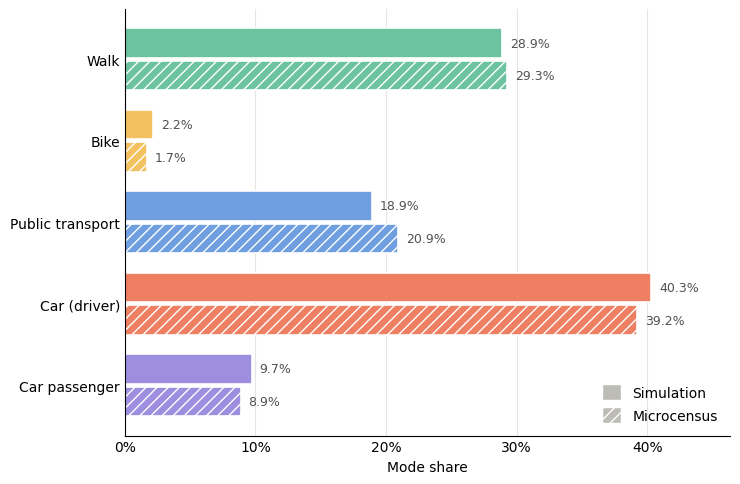

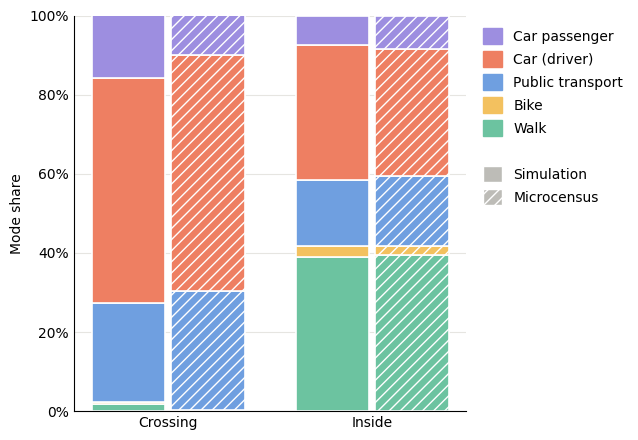

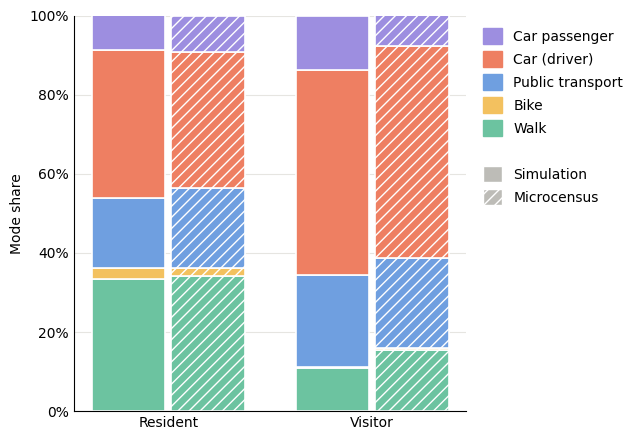

In [45]:
# %% 6. Aggregated mode share --------------------------------------------------------
agg = compare(sim_t, mz_t)
#print(agg); agg.to_csv(OUT_DIR / 'mode_share_total.csv')

by_class = compare(sim_t, mz_t, 'trip_class')
#tidy(by_class); by_class.to_csv(OUT_DIR / 'mode_share_trip_class.csv')

by_home = compare(sim_t, mz_t, 'home_in')
#tidy(by_home); by_home.to_csv(OUT_DIR / 'mode_share_residents_visitors.csv')

plot_total(sim_t, mz_t, 'Mode share of trips touching Lausanne', 'mode_share_total.png')
plot_compare(sim_t, mz_t, 'trip_class', 'Mode share by trip class', 'mode_share_trip_class.png')
plot_compare(sim_t, mz_t, 'home_in', 'Mode share by place of residence', 'mode_share_residence.png')

            sim                                        mz                \
mode       walk   bike     pt    car car_passenger   walk   bike     pt   
dist_bin                                                                  
<0.5      0.865  0.013  0.021  0.083         0.018  0.878  0.013  0.011   
0.5-1     0.545  0.040  0.106  0.256         0.054  0.439  0.033  0.146   
1-2       0.181  0.053  0.244  0.427         0.095  0.154  0.025  0.325   
2-5       0.043  0.030  0.289  0.521         0.116  0.028  0.033  0.315   
5-10      0.007  0.009  0.256  0.601         0.126  0.006  0.000  0.240   
>10       0.001  0.001  0.194  0.641         0.162  0.000  0.000  0.144   

                              diff_pp                                     n_mz  
mode        car car_passenger    walk   bike     pt    car car_passenger        
dist_bin                                                                        
<0.5      0.075         0.022  -1.296  0.037  0.992  0.759        -0.492  1553  


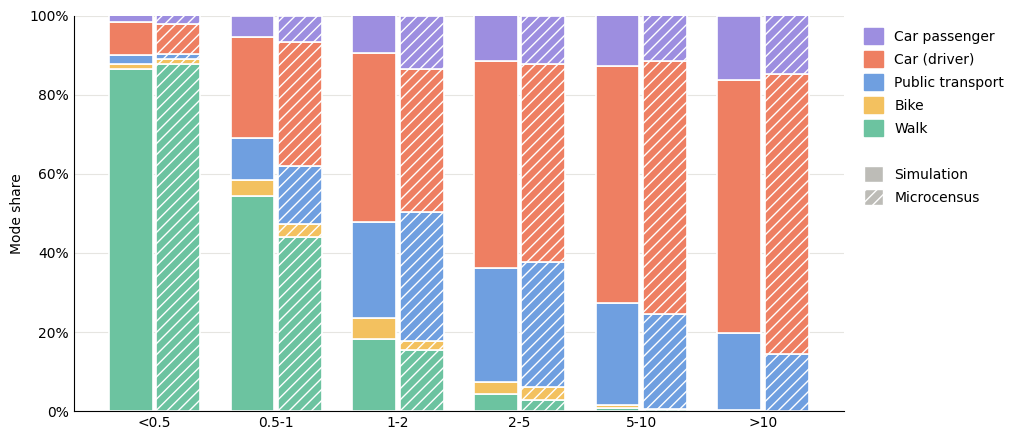

car share inside  sim 34.1%  MZ 32.1%  diff +2.0 pp
  from trip lengths: +1.6 pp
  from mode choice:  +0.4 pp
trip-length distribution:
            sim     mz
dist_km              
<0.5     0.298  0.334
0.5-1    0.160  0.167
1-2      0.186  0.166
2-5      0.241  0.227
5-10     0.100  0.083
>10      0.016  0.024


In [52]:
# %% 7. Mode share by distance (inside trips) ------------------------------------------
for df in (sim_i, mz_i):
    df['dist_bin'] = pd.cut(df['dist_km'], DIST_BINS, labels=DIST_LABELS, include_lowest=True)
by_dist = compare(sim_i, mz_i, 'dist_bin')
print(by_dist); by_dist.to_csv(OUT_DIR / 'mode_share_distance.csv')
plot_compare(sim_i, mz_i, 'dist_bin', 'Mode share by crow-fly distance [km], inside trips', 'mode_share_distance.png')
dist_distr = pd.DataFrame({'sim': weighted_dist(sim_i, 'dist_km', DIST_BINS, DIST_LABELS),
                           'mz': weighted_dist(mz_i, 'dist_km', DIST_BINS, DIST_LABELS)}).round(3)


# How much of the car difference comes from trip lengths vs. mode choice?
f = 'car'
car_by_bin_sim = shares(sim_i, 'dist_bin')[f]
car_by_bin_mz  = shares(mz_i,  'dist_bin')[f]
dist_sim = dist_distr['sim']
dist_mz  = dist_distr['mz']

total_sim = (dist_sim * car_by_bin_sim).sum()
total_mz  = (dist_mz  * car_by_bin_mz).sum()
sim_choice_mz_lengths = (dist_mz * car_by_bin_sim).sum()   # sim choices, MZ trip lengths

print(f'car share inside  sim {total_sim:.1%}  MZ {total_mz:.1%}  diff {100*(total_sim-total_mz):+.1f} pp')
print(f'  from trip lengths: {100*(total_sim - sim_choice_mz_lengths):+.1f} pp')
print(f'  from mode choice:  {100*(sim_choice_mz_lengths - total_mz):+.1f} pp')

print('trip-length distribution:\n', dist_distr)


--- car availability ---
              sim                                        mz                \
mode        walk   bike     pt    car car_passenger   walk   bike     pt   
car_avail                                                                  
always     0.186  0.014  0.122  0.610         0.067  0.217  0.012  0.108   
never      0.429  0.031  0.338  0.001         0.201  0.411  0.013  0.355   
sometimes    NaN    NaN    NaN    NaN           NaN  0.356  0.027  0.282   

                               diff_pp                                     \
mode         car car_passenger    walk   bike     pt    car car_passenger   
car_avail                                                                   
always     0.620         0.043  -3.118  0.271  1.432 -0.986          2.40   
never      0.048         0.172   1.856  1.784 -1.755 -4.715          2.83   
sometimes  0.250         0.085     NaN    NaN    NaN    NaN           NaN   

           n_mz  
mode             
car_avail        

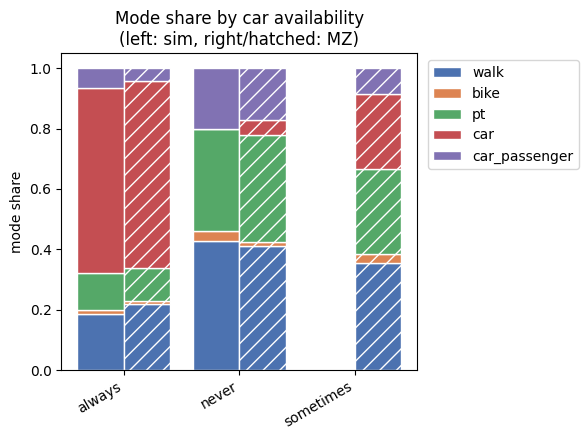


--- driving licence ---
            sim                                        mz                       \
mode      walk   bike     pt    car car_passenger   walk   bike     pt    car   
licence                                                                         
no       0.430  0.031  0.321  0.002         0.217  0.429  0.009  0.372  0.007   
yes      0.202  0.016  0.143  0.569         0.070  0.247  0.016  0.150  0.531   

                      diff_pp                                     n_mz  
mode    car_passenger    walk   bike     pt    car car_passenger        
licence                                                                 
no              0.182   0.061  2.141 -5.158 -0.469         3.426  1844  
yes             0.055  -4.517 -0.046 -0.793  3.788         1.568  5071  


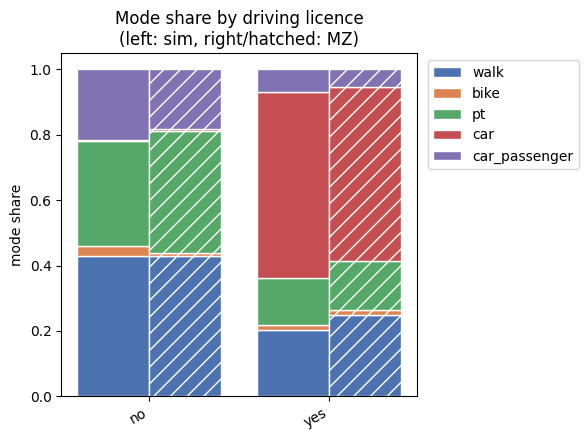


--- age ---
              sim                                        mz                \
mode        walk   bike     pt    car car_passenger   walk   bike     pt   
age_group                                                                  
[6, 18)    0.488  0.045  0.256  0.000         0.211  0.452  0.011  0.275   
[18, 25)   0.244  0.019  0.303  0.303         0.130  0.249  0.025  0.361   
[25, 45)   0.239  0.017  0.194  0.474         0.077  0.280  0.018  0.215   
[45, 65)   0.197  0.019  0.137  0.572         0.075  0.249  0.012  0.147   
[65, 120)  0.256  0.004  0.130  0.460         0.151  0.347  0.002  0.164   

                               diff_pp                                     \
mode         car car_passenger    walk   bike     pt    car car_passenger   
age_group                                                                   
[6, 18)    0.000         0.262   3.603  3.366 -1.879  0.000        -5.091   
[18, 25)   0.271         0.095  -0.455 -0.580 -5.769  3.228         3

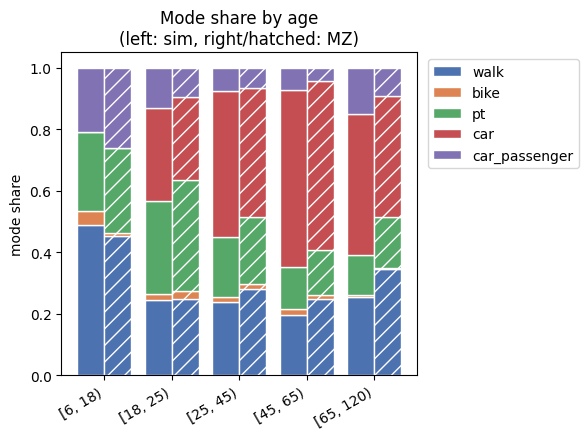


--- sex ---
           sim                                        mz                       \
mode     walk   bike     pt    car car_passenger   walk   bike     pt    car   
sex_                                                                           
female  0.288  0.015  0.211  0.348         0.138  0.332  0.010  0.225  0.331   
male    0.233  0.024  0.165  0.501         0.078  0.257  0.019  0.193  0.458   

                     diff_pp                                     n_mz  
mode   car_passenger    walk   bike     pt    car car_passenger        
sex_                                                                   
female         0.103  -4.394  0.501 -1.368  1.708         3.554  3655  
male           0.073  -2.399  0.470 -2.790  4.297         0.422  3260  


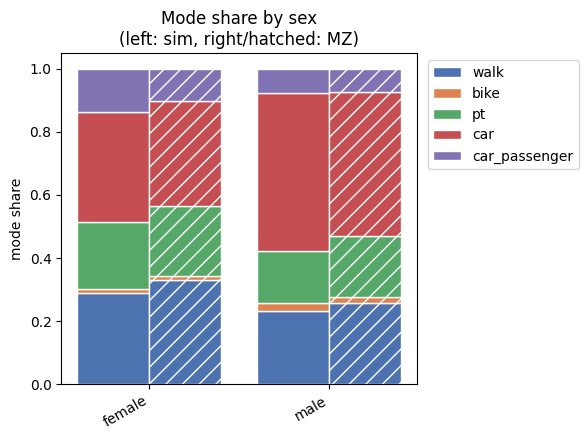


--- PT subscription ---
                  sim                                       mz                \
mode            walk  bike     pt    car car_passenger   walk   bike     pt   
pt_pass                                                                       
none            0.26  0.02  0.187  0.426         0.107  0.278  0.004  0.047   
GA               NaN   NaN    NaN    NaN           NaN  0.289  0.018  0.513   
half-fare        NaN   NaN    NaN    NaN           NaN  0.337  0.048  0.119   
regional/route   NaN   NaN    NaN    NaN           NaN  0.299  0.004  0.469   

                                    diff_pp                         \
mode              car car_passenger    walk   bike      pt     car   
pt_pass                                                              
none            0.567         0.104  -1.814  1.507  14.091 -14.079   
GA              0.127         0.053     NaN    NaN     NaN     NaN   
half-fare       0.448         0.048     NaN    NaN     NaN     NaN   


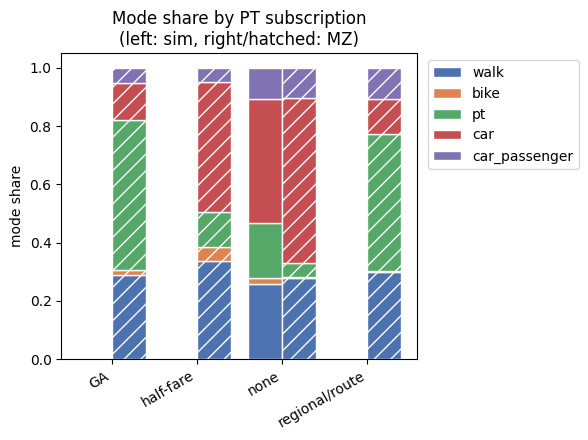

In [ ]:
# %% 8. Mode share by socio-demographics -----------------------------------------------
for col, title in [('car_avail', 'car availability'), ('licence', "driving licence"),
                   ('age_group', 'age'), ('sex_', 'sex'), ('pt_pass', 'PT subscription')]:
    if col in sim_t and col in mz_t and sim_t[col].notna().any():
        res = compare(sim_t, mz_t, col)
        print(f'\n--- {title} ---\n', res); res.to_csv(OUT_DIR / f'mode_share_{col}.csv')
        plot_compare(sim_t, mz_t, col, f'Mode share by {title}', f'mode_share_{col}.png')


          sim                                        mz                       \
mode     walk   bike     pt    car car_passenger   walk   bike     pt    car   
ring                                                                           
0-1 km  0.354  0.017  0.375  0.219         0.036  0.487  0.014  0.278  0.182   
1-2 km  0.380  0.024  0.216  0.313         0.066  0.340  0.018  0.242  0.326   
2-4 km  0.342  0.027  0.185  0.356         0.090  0.313  0.012  0.179  0.402   
4-7 km  0.222  0.019  0.181  0.458         0.120  0.250  0.017  0.135  0.480   
>7 km   0.130  0.013  0.099  0.597         0.161  0.128  0.013  0.212  0.535   

                     diff_pp                                      n_mz  
mode   car_passenger    walk   bike      pt    car car_passenger        
ring                                                                    
0-1 km         0.038 -13.301  0.260   9.644  3.671        -0.273  1422  
1-2 km         0.074   4.022  0.616  -2.589 -1.315        -0.735   

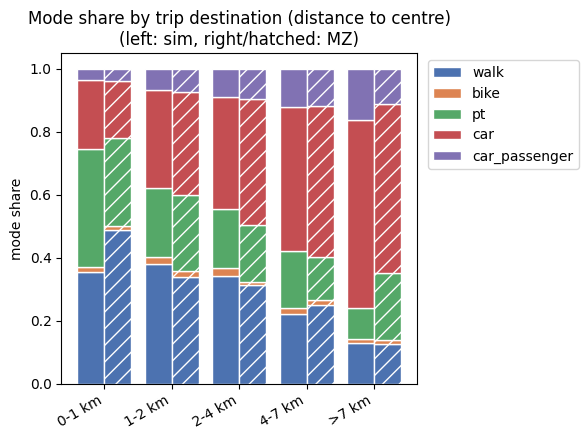

In [ ]:
# %% 9. Spatial differences: rings around Lausanne centre (by trip destination) ------
# Destination, because for parking it matters where the car ends up.
cx, cy = LAUSANNE_CENTER
for df in (sim_t, mz_t):
    df['ring'] = pd.cut(np.hypot(df['dx'] - cx, df['dy'] - cy) / 1000, RING_BINS, labels=RING_LABELS)
by_ring = compare(sim_t, mz_t, 'ring')
print(by_ring); by_ring.to_csv(OUT_DIR / 'mode_share_ring.csv')
plot_compare(sim_t, mz_t, 'ring', 'Mode share by trip destination (distance to centre)', 'mode_share_ring.png')

In [13]:
# %% 10. Car / parking --------------------------------------------------------------
f = FOCUS_MODE
car_s = sim_t[sim_t['mode'] == f].copy()
car_m = mz_t[mz_t['mode'] == f].copy()
print(f'MZ {f} trips touching the region (unweighted): {len(car_m):,}')

# (a) car share by purpose of the destination activity
by_purp = compare(sim_t, mz_t, 'purpose')
print(by_purp[[('sim', f), ('mz', f), ('diff_pp', f), ('n_mz', '')]])

# (b) where cars arrive: purpose mix of car trips that end inside Lausanne
end_in_s, end_in_m = inside(car_s['dx'], car_s['dy']), inside(car_m['dx'], car_m['dy'])
purp_mix = pd.DataFrame({'sim': wshare(car_s[end_in_s], 'purpose'),
                         'mz': wshare(car_m[end_in_m], 'purpose')}).round(3)
print('purpose of car trips ending in Lausanne:\n', purp_mix)

# (c) arrival-time profile of car trips ending inside Lausanne (parking demand over the day)
hours = range(0, 30)
arr = pd.DataFrame({
    'sim': car_s[end_in_s].groupby(car_s.loc[end_in_s, 'arr_h'].floordiv(1))['weight'].sum(),
    'mz':  car_m[end_in_m].groupby(car_m.loc[end_in_m, 'arr_h'].floordiv(1))['weight'].sum()}
).reindex(hours).fillna(0)
arr = arr / arr.sum()
plot_profiles(arr['sim'], arr['mz'], 'Arrival hour of car trips ending in Lausanne', 'hour', 'car_arrival_profile.png')

# (d) parking duration = time until the same person's NEXT CAR TRIP.
#     car_s / car_m contain only car-driver trips (already in trip order from steps 1 and 3),
#     so shift(-1) within a person gives that person's next car trip.
#     The last car trip of the day has no next one -> NaN -> excluded (no overnight parking).
for df, person in ((car_s, 'person'), (car_m, 'HHNR')):
    nxt = df.groupby(person)
    df['next_car_dep_h'] = nxt['dep_h'].shift(-1)
    df['park_h'] = df['next_car_dep_h'] - df['arr_h']

    # check: does the next car trip start where the car was left?
    gap_m = np.hypot(nxt['ox'].shift(-1) - df['dx'], nxt['oy'].shift(-1) - df['dy'])
    print(f'{person}: next car trip starts within 200 m of the parked car:',
          round((gap_m.dropna() < 200).mean(), 3))

# (d) parking duration = time until the person's next departure (last trip of the day excluded)
for df in (car_s, car_m):
    df['park_h'] = df['next_dep_h'] - df['arr_h']
dur = pd.DataFrame({'sim': weighted_dist(car_s[end_in_s & car_s['park_h'].ge(0)], 'park_h', DUR_BINS, DUR_LABELS),
                    'mz':  weighted_dist(car_m[end_in_m & car_m['park_h'].ge(0)], 'park_h', DUR_BINS, DUR_LABELS)}).round(3)
print('parking duration in Lausanne (car trips, excl. last trip of day):\n', dur)
plot_profiles(dur['sim'], dur['mz'], 'Parking duration after car trips ending in Lausanne', 'duration', 'car_parking_duration.png')
ps, pm = car_s[end_in_s & car_s['park_h'].ge(0)], car_m[end_in_m & car_m['park_h'].ge(0)]
dur_purp = pd.DataFrame({
    'sim_median_h': ps.groupby('purpose')['park_h'].median(),
    'mz_median_h':  pm.groupby('purpose')['park_h'].median(),
    'n_mz':         pm.groupby('purpose').size()}).round(2)
print(dur_purp); dur_purp.to_csv(OUT_DIR / 'car_parking_duration_by_purpose.csv')

# (e) car distance distribution (inside trips) and very short car trips
car_dist = pd.DataFrame({'sim': weighted_dist(sim_i[sim_i['mode'] == f], 'dist_km', DIST_BINS, DIST_LABELS),
                         'mz':  weighted_dist(mz_i[mz_i['mode'] == f], 'dist_km', DIST_BINS, DIST_LABELS)}).round(3)
print('car trip-length distribution (inside trips):\n', car_dist)

# (f) car trips (touching the region) per person per day. MZ person weights are
# normalised to the sample, not to the population, so compare rates, not totals.
mz_persons = mz.drop_duplicates('HHNR')
print('car trips per person per day  sim:', round(len(car_s) / sim['person'].nunique(), 3),
      ' MZ:', round(car_m['weight'].sum() / mz_persons['weight'].sum(), 3))

# (g) parking in the MZ (not represented in the simulation)
work_in = mz_t[(mz_t['purpose'] == 'work') & inside(mz_t['dx'], mz_t['dy'])]

# car share of work trips into Lausanne, by parking at the workplace
print(shares(work_in, 'work_parking')['car'].round(3))
print('n:', work_in.groupby('work_parking').size().to_dict())
print('simulation, all work trips into Lausanne:',
      round(shares(sim_t[(sim_t['purpose'] == 'work') & inside(sim_t['dx'], sim_t['dy'])])['car'], 3))

# car-driver trips into Lausanne: how many pay for parking, and how much
paid = car_m[end_in_m & car_m['park_fee'].notna()]
print('share paying for parking:', round(np.average(paid['park_fee'] > 0, weights=paid['weight']), 3))
print('median fee when paying [CHF]:', paid.loc[paid['park_fee'] > 0, 'park_fee'].median())
print(paid.groupby('purpose').apply(lambda d: np.average(d['park_fee'] > 0, weights=d['weight'])).round(3))

NameError: name 'sim_t' is not defined

In [ ]:
# %% 11. Traffic counts and GEH ---------------------------------------------------------
def geh(m, c):
    return np.sqrt(2 * (m - c) ** 2 / (m + c).replace(0, np.nan))

cc_file = SIM_DIR / 'ITERS' / f'it.{LAST_ITER}' / f'{LAST_ITER}.countscompare.txt'
if cc_file.exists():
    cc = pd.read_csv(cc_file, sep='\t')
    print(cc.columns.tolist())
    cc = cc.iloc[:, :4]; cc.columns = ['link', 'hour', 'sim', 'obs']
    # MATSim already scales 'sim' with countsScaleFactor (check output_config.xml says 10)
    cc['geh'] = geh(cc['sim'], cc['obs'])
    print('hourly values with GEH < 5:', round((cc['geh'] < 5).mean(), 3), '(target >= 0.85)')
    print(cc.groupby('hour')['geh'].median().round(2))
    peak = cc[cc['hour'].isin([8, 18])]                 # 7-8h and 17-18h (MATSim hours are 1-based)
    print('peak-hour GEH < 5:', round((peak['geh'] < 5).mean(), 3))
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.scatter(cc['obs'], cc['sim'], s=6, alpha=0.4)
    lim = max(cc['obs'].max(), cc['sim'].max()); ax.plot([0, lim], [0, lim], 'k--', lw=1)
    ax.set_xlabel('observed [veh/h]'); ax.set_ylabel('simulated [veh/h]'); ax.set_title('Hourly counts')
    fig.tight_layout(); fig.savefig(OUT_DIR / 'counts_scatter.png', dpi=150); plt.show()
else:
    print('No countscompare file; using the daily counts file instead.')
    daily = pd.read_csv(SIM_DIR / 'output_traffic_flow_daily_counts.csv', sep=None, engine='python')
    print(daily.columns.tolist()); print(daily.head())
    # set the column names after checking the printout; scale sim by 1/SAMPLE_SIZE if unscaled:
    # daily['geh'] = geh(daily['<sim col>'] / SAMPLE_SIZE, daily['<obs col>'])
    # GEH < 5 is an hourly criterion; for daily totals state which threshold you use.

No countscompare file; using the daily counts file instead.
['linkId', 'dailyCount']
    linkId  dailyCount
0  1001821       131.0
1  1001859      1377.0
2  1001860      1339.0
3  1001861      1188.0
4  1001879       106.0


#### Check mode-share in distance bins

#### Check mode-share by at least two socio-demographics of your choice (relevant for your project)

#### Check the spatial difference in mode-choice

#### Focus on the transport mode relevant for your project. Is it reliable enough? Is something missing?

#### Validate some of the traffic counts on your network? What GEH do you obtain?

# OLD

In [ ]:
def flag(col):
    """True where a boolean-like person attribute is set."""
    return sim[col].astype(str).str.lower().isin(['true', '1', 'yes'])

In [ ]:
for c in ['sex', 'carAvail', 'hasLicense', 'subscriptions', 'isOutside', 'subpopulation', 'municipalityType']:
    print(c, persons[c].value_counts(dropna=False).head(8).to_dict())

In [ ]:
# %% 3. Microcensus ---------------------------------------------------------------
zp = read_mz('zielpersonen.csv', ['HHNR', 'WP', 'alter', 'gesl', 'tag', 'f20400a', 'f42100e',
                                   'f41610a', 'f41610b', 'f41610c', 'f41610d', 'ERWERB'])
hh = read_mz('haushalte.csv', ['HHNR', 'F20601'])
wege = read_mz('wege.csv', ['HHNR', 'WEGNR', 'wmittel', 'w_dist_obj2', 'wzweck1',
                            'f51100', 'f51400',
                            'S_X_CH1903', 'S_Y_CH1903', 'Z_X_CH1903', 'Z_Y_CH1903',
                            'W_X_CH1903', 'W_Y_CH1903'])
et = read_mz('etappen.csv', ['HHNR', 'WEGNR', 'ETNR', 'f51300', 'rdist'])

# main mode: wmittel 2-7 PT, 9 car (driver+passenger), 14 bike/e-bike, 15 walk,
# 16 scooter/skates -> walk; plane, coach, truck, taxi, motorbike, moped, other -> 'other'
WMITTEL = {2: 'pt', 3: 'pt', 4: 'pt', 5: 'pt', 6: 'pt', 7: 'pt',
           9: 'car', 14: 'bike', 15: 'walk', 16: 'walk'}
wege = wege[wege['wmittel'] != -99]                     # trips containing pseudo stages
wege['mode'] = wege['wmittel'].map(WMITTEL).fillna('other')

# driver vs passenger from the longest car stage (f51300: 7 driver, 8 passenger)
car_et = et[et['f51300'].isin([7, 8])].sort_values('rdist').groupby(['HHNR', 'WEGNR']).last()
role = car_et['f51300'].map({7: 'car', 8: 'car_passenger'}).rename('car_role')
wege = wege.merge(role, left_on=['HHNR', 'WEGNR'], right_index=True, how='left')
wege.loc[wege['mode'] == 'car', 'mode'] = wege['car_role'].fillna('car')

mz = wege.merge(zp, on='HHNR').merge(hh, on='HHNR', how='left')
mz = mz[mz['tag'].between(1, 5)].copy()                 # simulation = average weekday
mz['weight']  = mz['WP']
mz['dist_km'] = mz['w_dist_obj2'].where(mz['w_dist_obj2'] >= 0)
for p in ['S', 'Z', 'W']:                               # CH1903/LV03 -> LV95
    mz[f'{p}x'] = mz[f'{p}_X_CH1903'].where(mz[f'{p}_X_CH1903'] > 0) + 2_000_000
    mz[f'{p}y'] = mz[f'{p}_Y_CH1903'].where(mz[f'{p}_Y_CH1903'] > 0) + 1_000_000
mz['ox'], mz['oy'], mz['dx'], mz['dy'] = mz['Sx'], mz['Sy'], mz['Zx'], mz['Zy']

ZWECK = {11: 'home', 2: 'work', 6: 'work', 7: 'work', 3: 'education', 4: 'shop', 8: 'leisure'}
mz['purpose'] = mz['wzweck1'].map(ZWECK).fillna('other')
mz = mz.sort_values(['HHNR', 'WEGNR'])
mz['dep_h'] = mz['f51100'].where(mz['f51100'] >= 0) / 60
mz['arr_h'] = mz['f51400'].where(mz['f51400'] >= 0) / 60
mz['next_dep_h'] = mz.groupby('HHNR')['dep_h'].shift(-1)

mz['work_parking'] = mz['f41300'].map({1: 'free', 2: 'paid', 3: 'none'})
mz['work_parking_cost'] = mz['f41400'].where(mz['f41400'] >= 0)